In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')


df = pd.read_csv('../files/world_bank_multidimensional_2018_2022.csv', encoding='utf-8-sig')

aggregates = ['WLD', 'ARB', 'EAS', 'ECS', 'LCN', 'MEA', 'SAS', 'SSF', 'EUU', 'EMU', 'OED', 'IDA', 'IBD', 'IBT', 'IDB', 'IDX', 'LDC', 'LTE', 'PRE', 'PST', 'HPC', 'LMY', 'MIC', 'XM', 'XN', 'XT', 'VGB', 'CHI', 'CSS', 'CEB', 'EAR', 'TEA', 'EAP', 'TEC', 'ECA', 'TMN', 'MNA', 'OSS', 'PSS', 'SST', 'TLA', 'TSA', 'TSS', 'SSA', 'AFE', 'AFW']
df_countries = df[~df['code'].isin(aggregates)].copy()

df_grouped = df_countries.groupby(['code', 'entity']).mean(numeric_only=True).reset_index()

features = ['internet_pct', 'gdp_pc_usd', 'birth_rate', 'death_rate', 'life_exp', 'urban_pct']


df_clean = df_grouped.dropna(subset=features).copy()

print(f"Стран для анализа: {len(df_clean)}")


scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[features])


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

Стран для анализа: 193


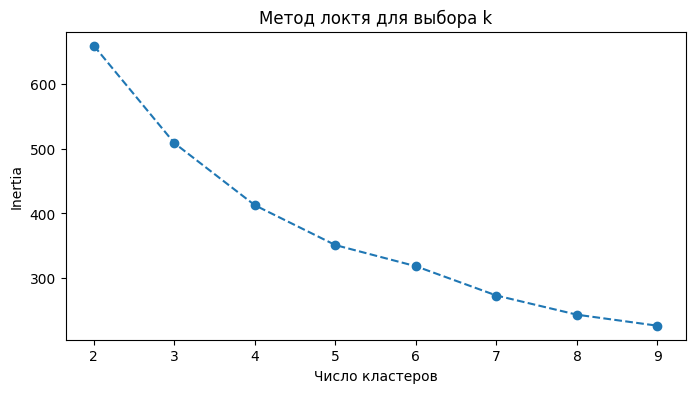

DBSCAN нашел кластеров: 1
Шумовых точек: 3


In [ ]:
inertia = []
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), inertia, marker='o', linestyle='--')
plt.title('Метод локтя для выбора k')
plt.xlabel('Число кластеров')
plt.ylabel('Inertia')
plt.show()


kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)


hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_hc = hc.fit_predict(X_scaled)


dbscan = DBSCAN(eps=1.5, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

print(f"DBSCAN нашел кластеров: {len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)}")
print(f"Шумовых точек: {sum(labels_dbscan == -1)}")

In [ ]:
def evaluate(X, labels, name):
    unique = set(labels)
    if len(unique) < 2 or (len(unique) == 2 and -1 in unique):
        return f"{name}: Недостаточно кластеров"
    
    mask = labels != -1
    if sum(mask) < 2:
        return f"{name}: Слишком много шума"
    
    sil = silhouette_score(X[mask], labels[mask])
    db = davies_bouldin_score(X[mask], labels[mask])
    ch = calinski_harabasz_score(X[mask], labels[mask])
    return f"{name}: Silhouette={sil:.3f}, Davies-Bouldin={db:.3f}, Calinski-Harabasz={ch:.1f}"

print(evaluate(X_scaled, labels_kmeans, "K-Means"))
print(evaluate(X_scaled, labels_hc, "Hierarchical"))
print(evaluate(X_scaled, labels_dbscan, "DBSCAN"))

K-Means: Silhouette=0.327, Davies-Bouldin=1.099, Calinski-Harabasz=121.2
Hierarchical: Silhouette=0.275, Davies-Bouldin=1.168, Calinski-Harabasz=101.6
DBSCAN: Недостаточно кластеров


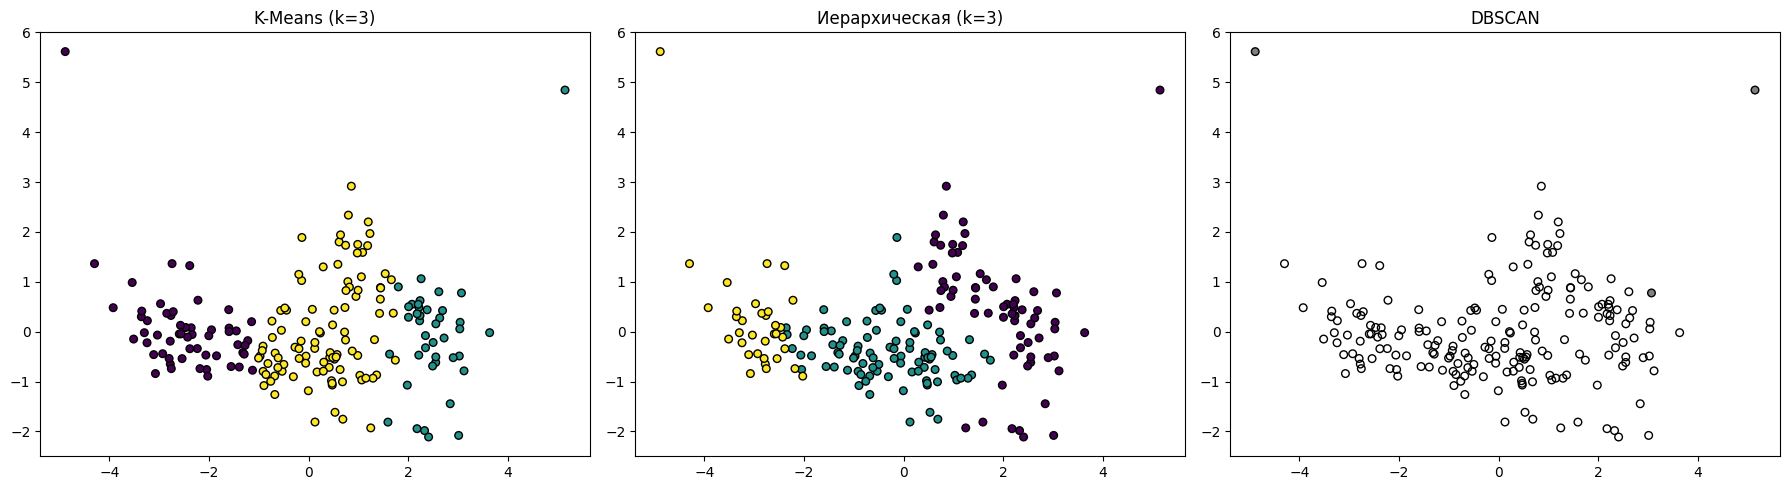

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_kmeans, cmap='viridis', s=30, edgecolor='k')
axes[0].set_title('K-Means (k=3)')


axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_hc, cmap='viridis', s=30, edgecolor='k')
axes[1].set_title('Иерархическая (k=3)')


colors_db = ['gray' if l == -1 else plt.cm.viridis(l / max(labels_dbscan)) for l in labels_dbscan]
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=colors_db, s=30, edgecolor='k')
axes[2].set_title('DBSCAN')

plt.tight_layout()
plt.show()

K-Means (безразмерные): Silhouette=0.386, Davies-Bouldin=0.719, Calinski-Harabasz=101.2


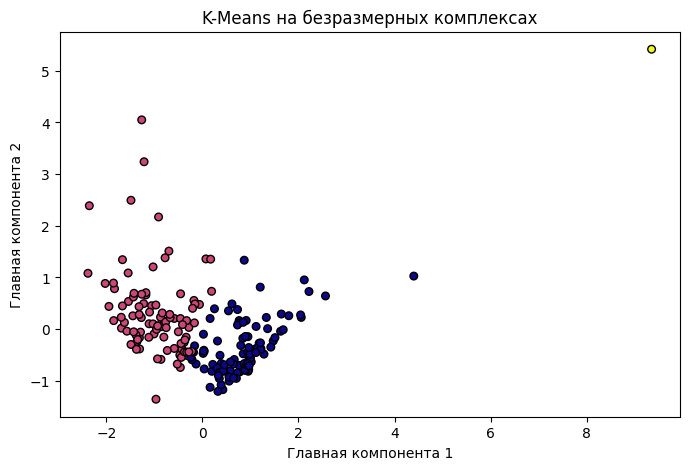

In [6]:
df_clean['gdp_per_life'] = df_clean['gdp_pc_usd'] / df_clean['life_exp']
df_clean['internet_urban_ratio'] = df_clean['internet_pct'] / df_clean['urban_pct']
df_clean['birth_death_ratio'] = df_clean['birth_rate'] / df_clean['death_rate']

dimless_features = ['gdp_per_life', 'internet_urban_ratio', 'birth_death_ratio']
X_dimless = df_clean[dimless_features]
X_dimless_scaled = scaler.fit_transform(X_dimless)

# K-Means на безразмерных данных
kmeans_dimless = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_dimless = kmeans_dimless.fit_predict(X_dimless_scaled)

print(evaluate(X_dimless_scaled, labels_dimless, "K-Means (безразмерные)"))

# Визуализация
pca_dimless = PCA(n_components=2)
X_pca_dimless = pca_dimless.fit_transform(X_dimless_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca_dimless[:, 0], X_pca_dimless[:, 1], c=labels_dimless, cmap='plasma', s=30, edgecolor='k')
plt.title('K-Means на безразмерных комплексах')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.show()

In [7]:
df_clean['cluster_kmeans'] = labels_kmeans
df_clean['cluster_dimless'] = labels_dimless

print("=== Средние значения исходных признаков по кластерам K-Means ===")
print(df_clean.groupby('cluster_kmeans')[features].mean().round(2))

print("\n=== Средние значения безразмерных комплексов по кластерам K-Means (безразмерный) ===")
print(df_clean.groupby('cluster_dimless')[dimless_features].mean().round(2))

=== Средние значения исходных признаков по кластерам K-Means ===
                internet_pct  gdp_pc_usd  birth_rate  death_rate  life_exp  \
cluster_kmeans                                                               
0                      29.21     1807.68       31.54        8.18     63.20   
1                      92.05    59835.56        9.95        7.85     82.00   
2                      72.00     9744.01       15.15        8.53     73.63   

                urban_pct  
cluster_kmeans             
0                   38.93  
1                   84.75  
2                   64.48  

=== Средние значения безразмерных комплексов по кластерам K-Means (безразмерный) ===
                 gdp_per_life  internet_urban_ratio  birth_death_ratio
cluster_dimless                                                       
0                      347.85                  1.29               1.33
1                       79.13                  0.84               4.18
2                     2148.06     